# Midterm Group Project — Group 6
**Java source code vulnerability detection: CodeBERT + LoRA (primary) vs DistilBERT + classification head (alternative)**

Management of Organizational Data · Master's programme · 2026
Team: Bakaev Eldos · Murziyev Adil · Zhazylbekov Zanggar

Data: X1 with P3 / X1 without P3 from [rmusab/vul-llm-finetune](https://github.com/rmusab/vul-llm-finetune/tree/main/Datasets) (Shestov et al., IEEE Access 2025).
The notebook runs the pipeline step by step. All the logic is in `src/`, so it can also run without Jupyter (see README).

In [1]:
import json, sqlite3, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import config
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RUN_TRAINING = False

def run(*args):
    out = subprocess.run([sys.executable, *args], cwd=ROOT, capture_output=True, text=True)
    print(out.stdout[-3000:], out.stderr[-2000:] if out.returncode else "")

## 1. Organizational data management — lifecycle
Acquisition → validation → storage → transformation → training → evaluation → retention/deletion. Each stage has an owner and a DAMA-DMBOK / ISO reference.

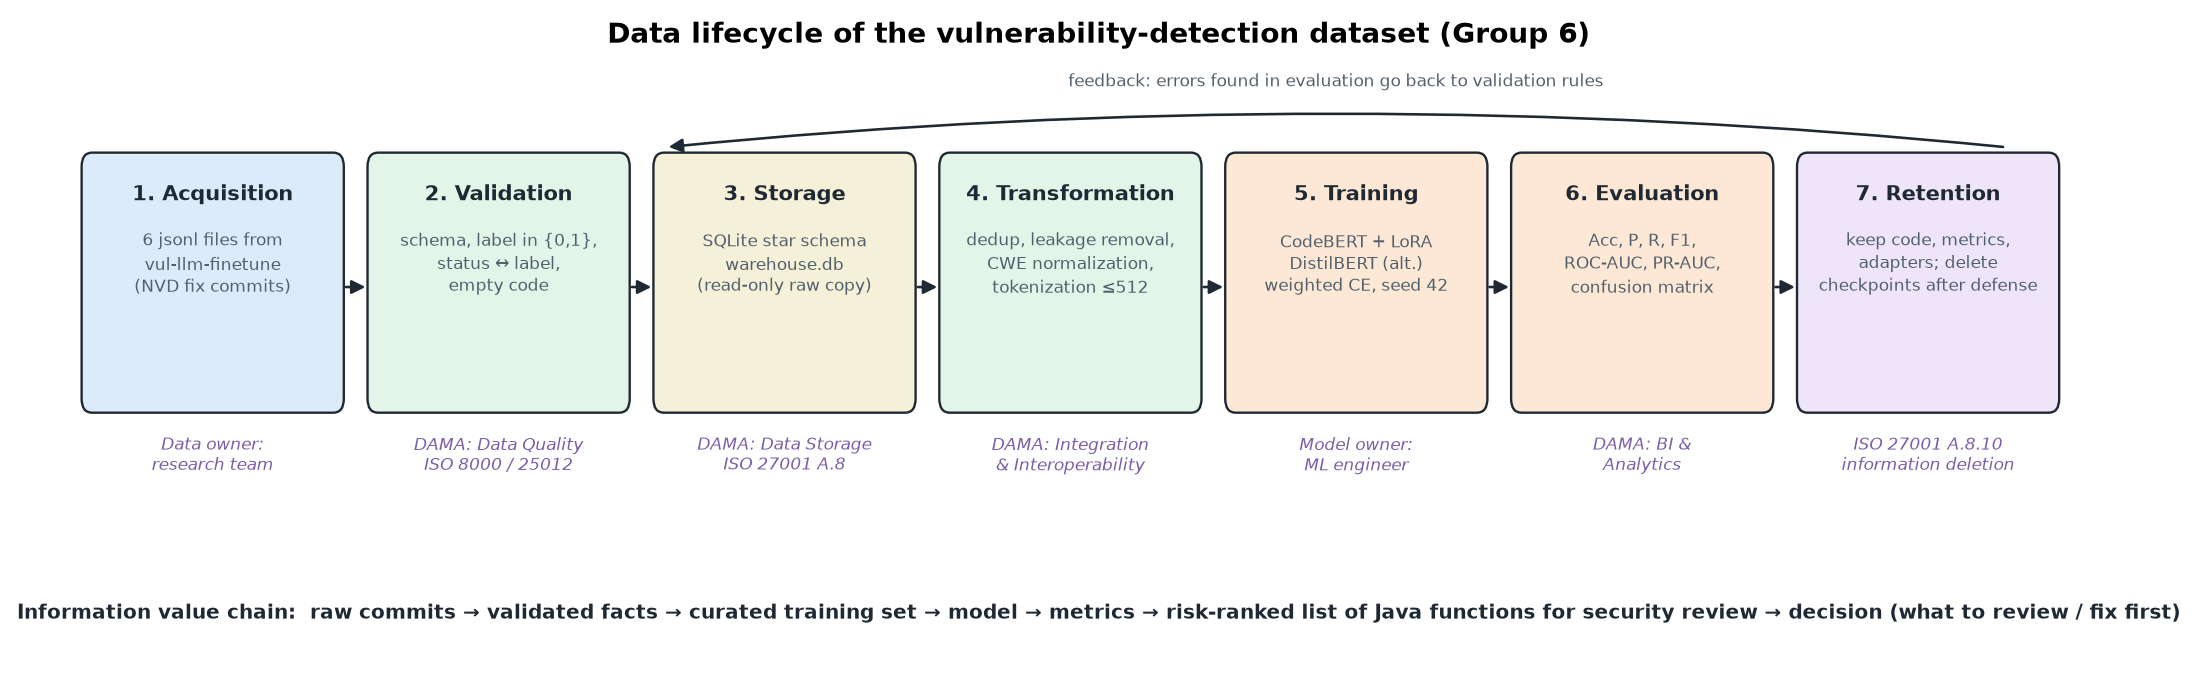

In [2]:
display(Image("results/figures/lifecycle.png"))

## 3. Data model (ER) and 4. ETL into the warehouse
`src/etl.py` extracts the six jsonl files, validates them, removes leakage and conflicting duplicates, and loads a SQLite star schema (`data/warehouse.db`) plus the ML-ready CSVs.

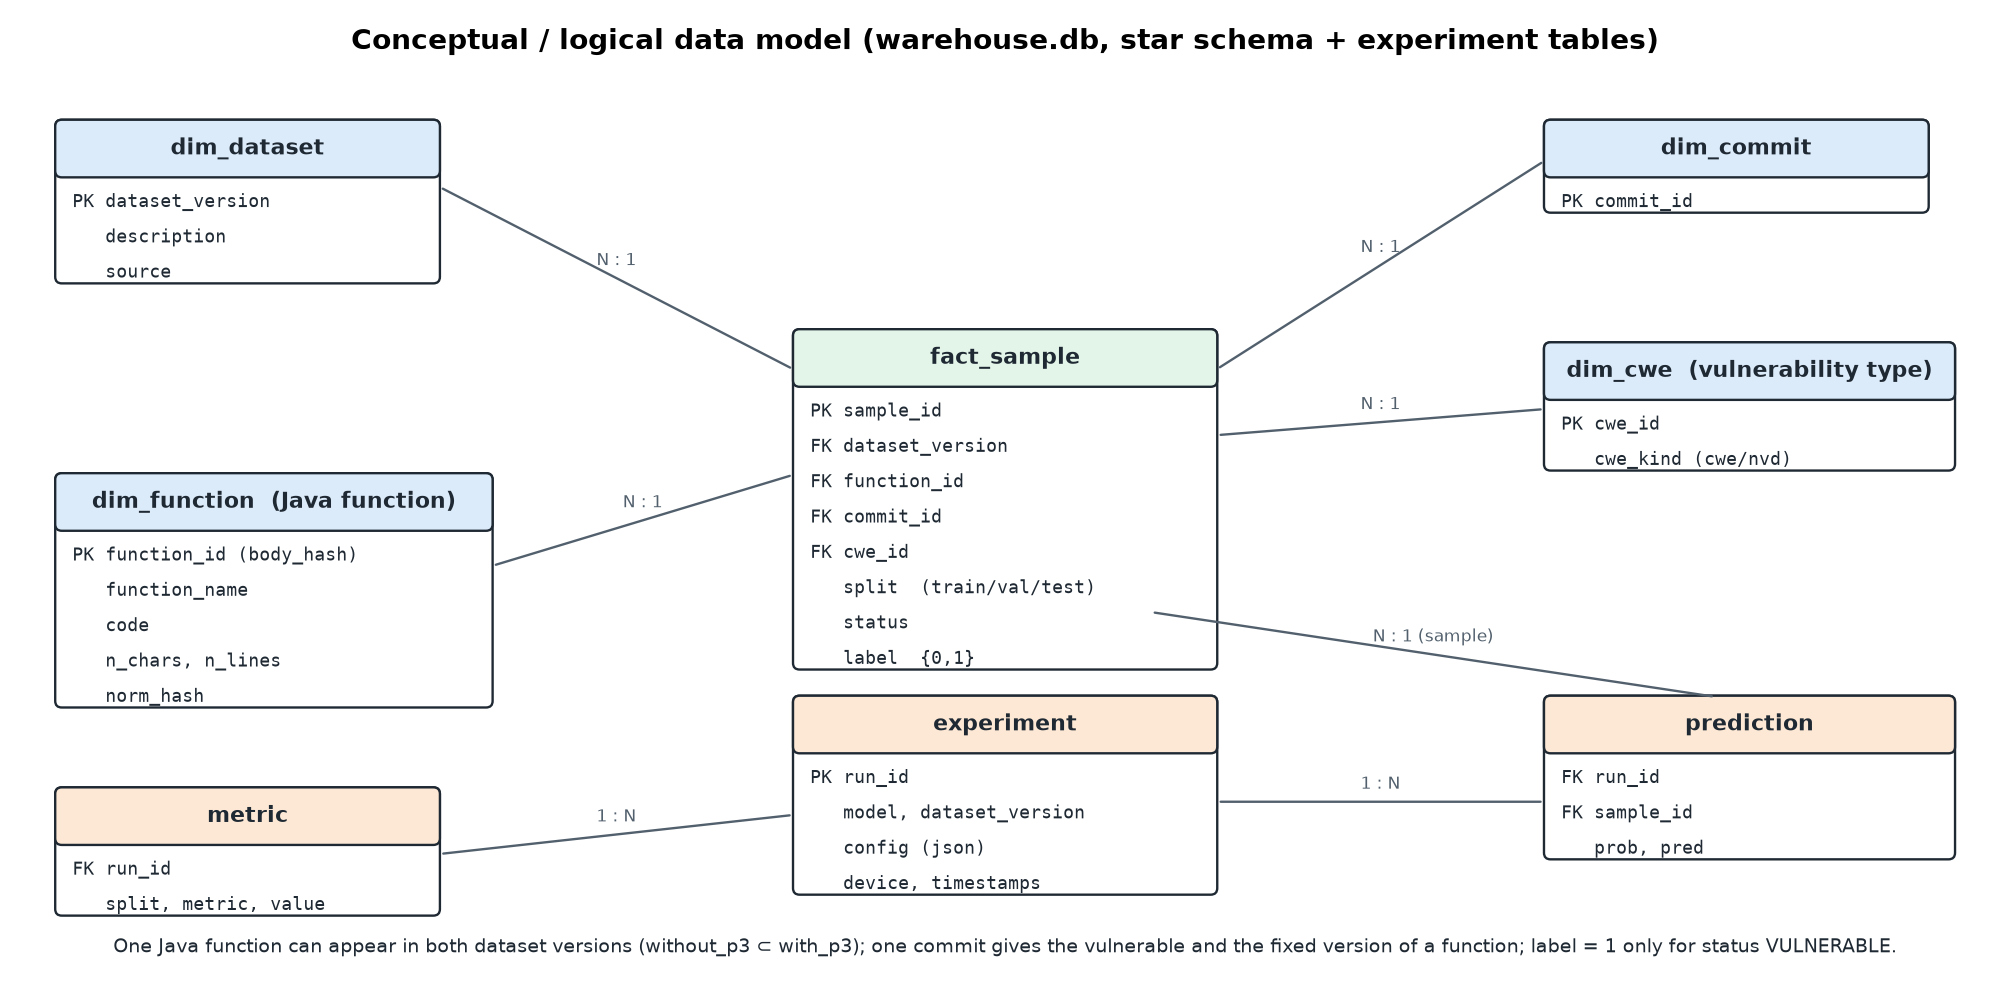

In [3]:
display(Image("results/figures/er_model.png"))

In [4]:
run("src/etl.py")

[extract] 24288 rows from 6 jsonl files
[transform] invalid label 0, status/label mismatch 0, empty code 0 -> dropped 0
[transform] same code with conflicting labels dropped 11
[transform] rows whose code also appears in another split (leakage) 76
[transform] normalized-code duplicates removed 72
[transform] 24288 -> 24205 rows
[load] {"dim_dataset": 2, "dim_commit": 839, "dim_cwe": 89, "dim_function": 22878, "fact_sample": 24205}
 


In [5]:
con = sqlite3.connect(config.WAREHOUSE)
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name.tolist())
pd.read_sql('''SELECT f.dataset_version, f.split, COUNT(*) n, SUM(label) pos, ROUND(100.0*AVG(label),2) pos_pct
               FROM fact_sample f GROUP BY 1,2 ORDER BY 1, CASE split WHEN 'train' THEN 0 WHEN 'val' THEN 1 ELSE 2 END''', con)

['experiment', 'metric', 'prediction', 'dim_dataset', 'dim_commit', 'dim_cwe', 'dim_function', 'fact_sample', 'etl_run']


,dataset_version,split,n,pos,pos_pct
0,with_p3,train,13214,395,2.99
1,with_p3,val,5115,129,2.52
2,with_p3,test,4545,117,2.57
3,without_p3,train,809,402,49.69
4,without_p3,val,271,139,51.29
5,without_p3,test,251,122,48.61


In [6]:
pd.read_sql("SELECT * FROM etl_run", con)

,run_at,step,detail
0,2026-10-30T11:38:10+00:00,extract,24288 rows from 6 jsonl files
1,2026-10-30T11:38:10+00:00,transform,"invalid label 0, status/label mismatch 0, empt..."
2,2026-10-30T11:38:10+00:00,transform,same code with conflicting labels dropped 11
3,2026-10-30T11:38:10+00:00,transform,rows whose code also appears in another split ...
4,2026-10-30T11:38:10+00:00,transform,normalized-code duplicates removed 72
5,2026-10-30T11:38:10+00:00,transform,24288 -> 24205 rows


## 5. Data quality

In [7]:
run("src/data_quality.py")
pd.read_csv("results/data_quality_table.csv", index_col=0)

{
 "before_etl": {
  "with_p3": {
   "rows": 22954,
   "completeness_%": 100.0,
   "unique_body_hash_%": 100.0,
   "unique_normalized_code_%": 99.669,
   "label_validity_%": 100.0,
   "status_label_consistency_%": 100.0,
   "cwe_proper_code_%": 86.05,
   "cwe_nvd_placeholder_%": 13.95,
   "commits_in_more_than_one_split": 0,
   "code_in_more_than_one_split": 37,
   "same_code_conflicting_labels": 4,
   "positive_%": 2.81,
   "neg_per_pos": 34.5
  },
  "without_p3": {
   "rows": 1334,
   "completeness_%": 100.0,
   "unique_body_hash_%": 100.0,
   "unique_normalized_code_%": 99.85,
   "label_validity_%": 100.0,
   "status_label_consistency_%": 100.0,
   "cwe_proper_code_%": 86.96,
   "cwe_nvd_placeholder_%": 13.04,
   "commits_in_more_than_one_split": 0,
   "code_in_more_than_one_split": 2,
   "same_code_conflicting_labels": 1,
   "positive_%": 49.85,
   "neg_per_pos": 1.0
  }
 },
 "after_etl": {
  "with_p3": {
   "rows": 22874,
   "completeness_%": 100.0,
   "unique_body_hash_%": 100.0,

,before_etl,before_etl.1,after_etl,after_etl.1
NaN,with_p3,without_p3,with_p3,without_p3
rows,22954.0,1334.0,22874.0,1331.0
completeness_%,100.0,100.0,100.0,100.0
unique_body_hash_%,100.0,100.0,100.0,100.0
unique_normalized_code_%,99.669,99.85,100.0,100.0
label_validity_%,100.0,100.0,100.0,100.0
status_label_consistency_%,100.0,100.0,100.0,100.0
cwe_proper_code_%,86.05,86.96,86.03,86.93
cwe_nvd_placeholder_%,13.95,13.04,13.97,13.07
commits_in_more_than_one_split,0.0,0.0,0.0,0.0


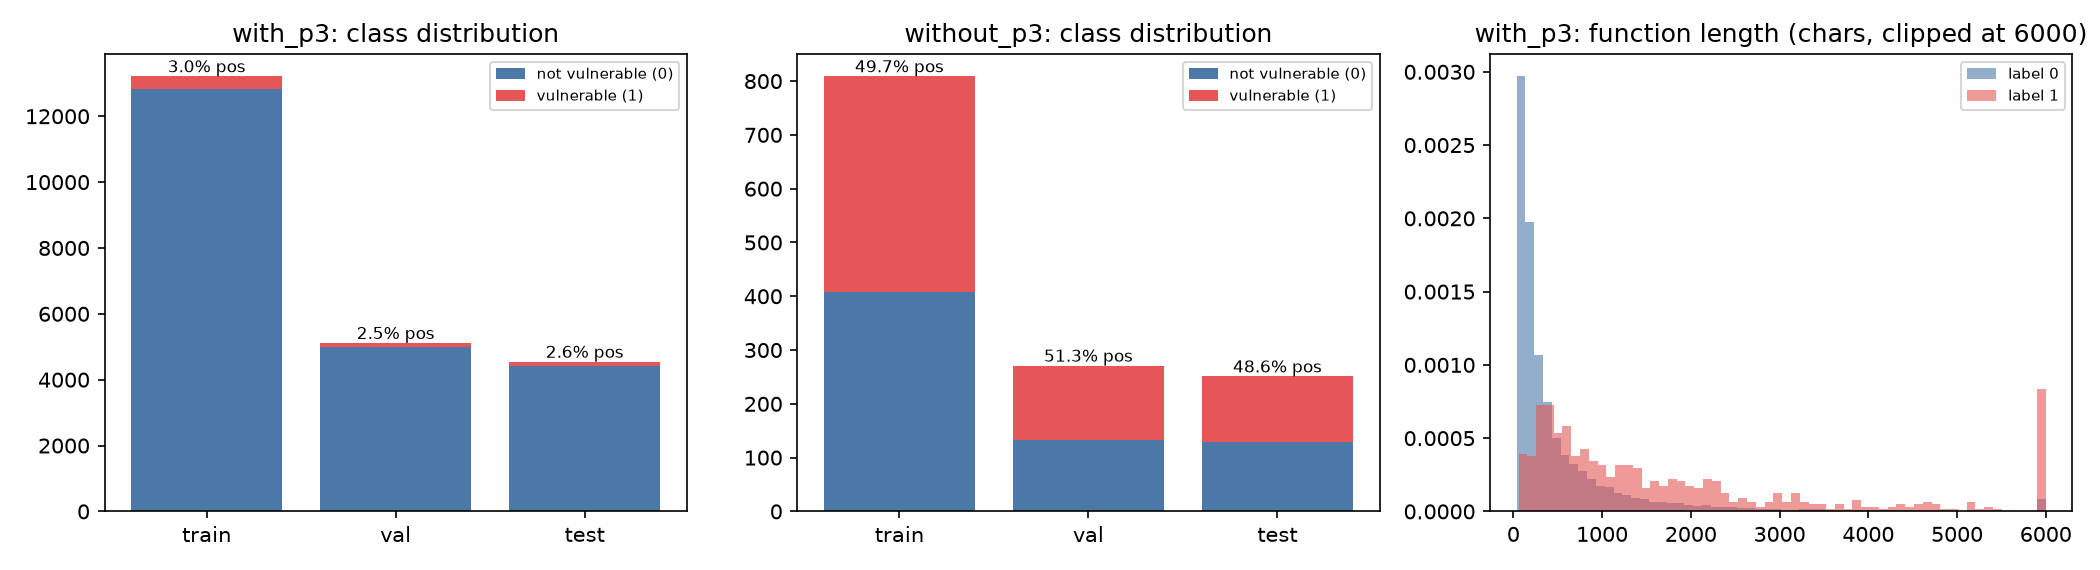

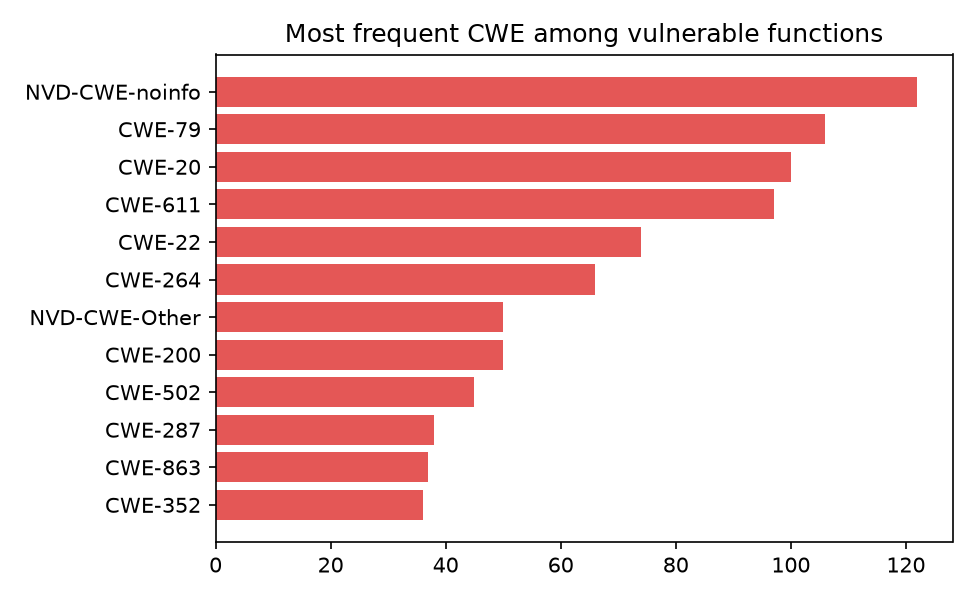

In [8]:
display(Image("results/figures/dq_class_and_length.png")); display(Image("results/figures/dq_top_cwe.png"))

## Model training (primary and alternative)
* **Primary — CodeBERT + LoRA**: `microsoft/codebert-base` (125M parameters, frozen). LoRA adapters (r = 16, α = 32) on the query/value projections, plus the classification head. Only ~1.1% of the weights are trained.
* **Alternative — DistilBERT + classification head**: full fine-tuning of `distilbert-base-uncased` (66M), a general English model with no code pre-training.
* **Classical reference** — TF-IDF over Java tokens + logistic regression.

All models use the same splits, the same seed (42), max 512 tokens, a class-weighted cross-entropy (positive weight = √(neg/pos) ≈ 5.7), model selection on validation PR-AUC, and a decision threshold chosen on validation F1.

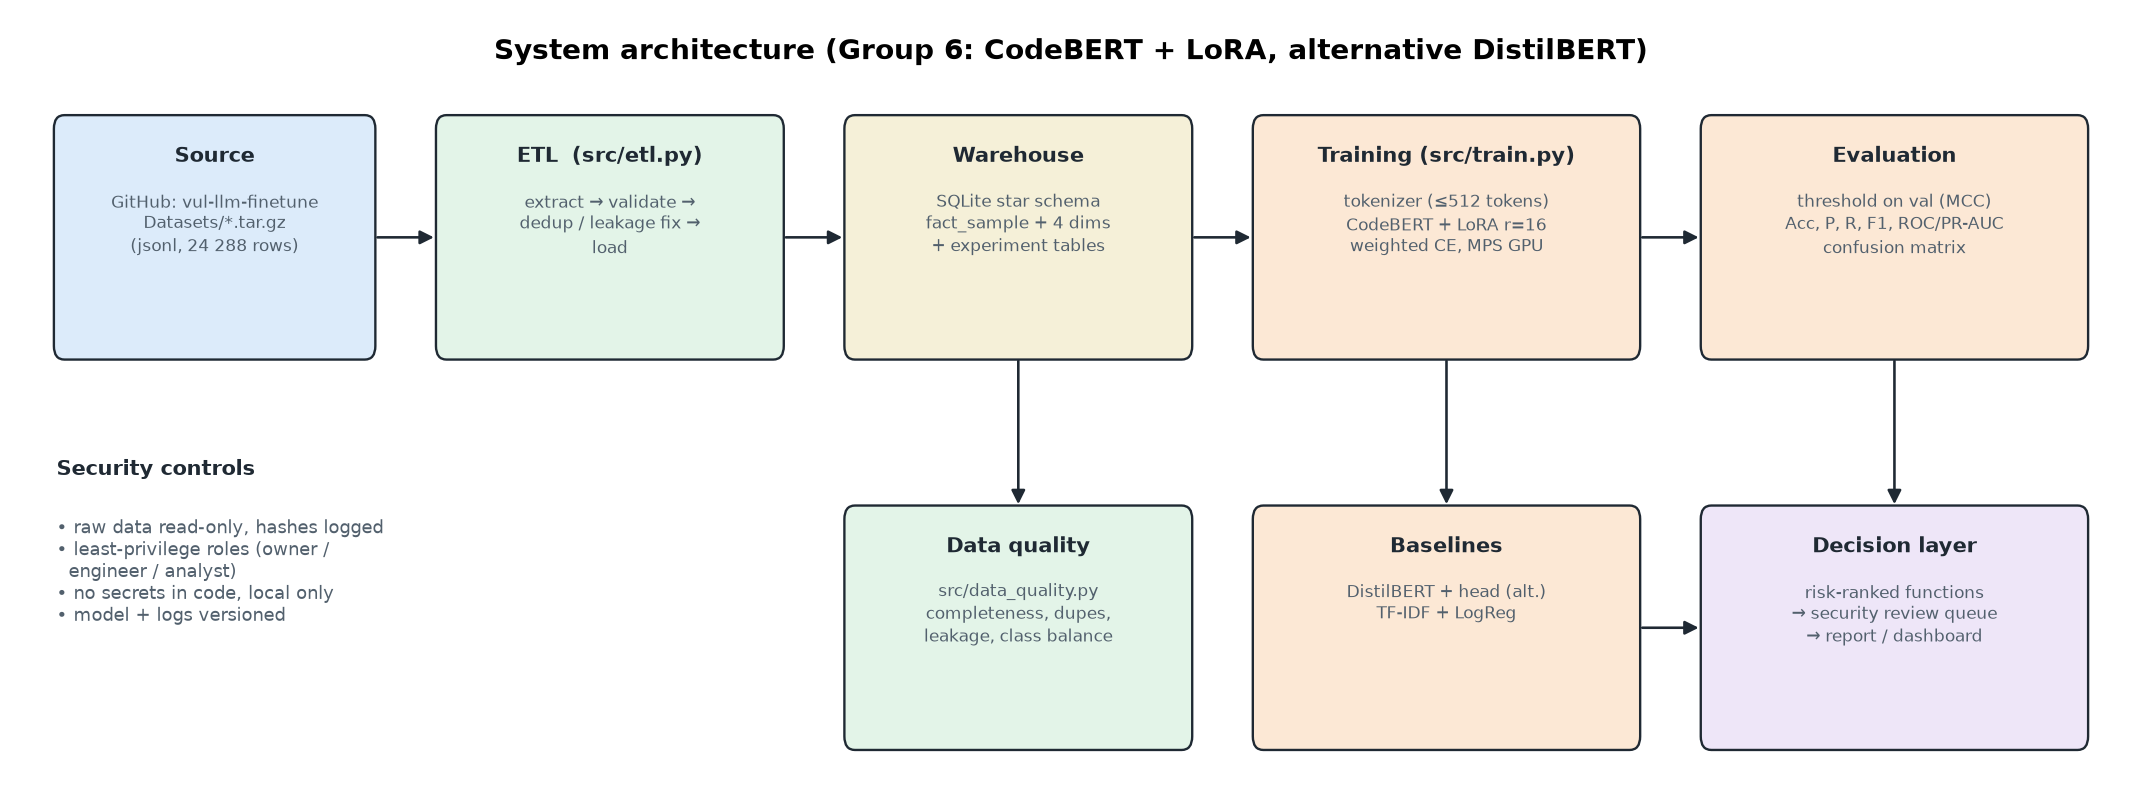

In [9]:
display(Image("results/figures/architecture.png"))

In [10]:
if RUN_TRAINING:
    for m in ("codebert_lora", "distilbert_head"):
        run("src/train.py", "--model", m, "--data", "with_p3")
    run("src/train.py", "--model", "codebert_lora", "--data", "without_p3")
    for d in ("with_p3", "without_p3"):
        run("src/baseline.py", "--data", d)
for f in sorted(Path("results/runs").glob("*/config.json")):
    c = json.loads(f.read_text())
    print(f"{c['run_id']:32s} trainable {c['trainable_params']:>11,} / {c['total_params']:>11,}  device {c['device']}")

codebert_lora_with_p3            trainable   1,181,954 / 125,829,124  device mps
codebert_lora_without_p3         trainable   1,181,954 / 125,829,124  device mps
distilbert_head_with_p3          trainable  66,955,010 /  66,955,010  device mps
distilbert_head_without_p3       trainable  66,955,010 /  66,955,010  device mps


In [11]:
print(Path("results/runs/codebert_lora_with_p3/train.log").read_text()[-2500:])

0/4956 loss 0.5074 (0.73s/step)
15:29:21  epoch 3 step 3650/4956 loss 0.2265 (0.73s/step)
15:29:47  epoch 3 step 3700/4956 loss 0.4072 (0.72s/step)
15:30:13  epoch 3 step 3750/4956 loss 0.2416 (0.72s/step)
15:30:45  epoch 3 step 3800/4956 loss 0.3771 (0.72s/step)
15:31:06  epoch 3 step 3850/4956 loss 0.4768 (0.72s/step)
15:31:36  epoch 3 step 3900/4956 loss 0.3913 (0.71s/step)
15:32:03  epoch 3 step 3950/4956 loss 0.3642 (0.71s/step)
15:32:34  epoch 3 step 4000/4956 loss 0.2920 (0.71s/step)
15:32:59  epoch 3 step 4050/4956 loss 0.3471 (0.71s/step)
15:33:25  epoch 3 step 4100/4956 loss 0.4257 (0.71s/step)
15:33:59  epoch 3 step 4150/4956 loss 0.4829 (0.71s/step)
15:34:36  epoch 3 step 4200/4956 loss 0.3173 (0.71s/step)
15:35:11  epoch 3 step 4250/4956 loss 0.3827 (0.71s/step)
15:35:42  epoch 3 step 4300/4956 loss 0.4969 (0.70s/step)
15:36:06  epoch 3 step 4350/4956 loss 0.1497 (0.70s/step)
15:36:30  epoch 3 step 4400/4956 loss 0.2970 (0.70s/step)
15:36:54  epoch 3 step 4450/4956 loss 0.

## 7. Analytics and visualization — evaluation

In [12]:
run("src/evaluate.py")
cmp = pd.read_csv("results/model_comparison.csv")
cmp.drop(columns=["threshold"]).round(3)

   dataset             model  accuracy  majority_baseline  balanced_acc  precision  recall    f1  roc_auc  pr_auc    mcc  threshold  trainable_params  triage_threshold  triage_accuracy  triage_precision  triage_recall  triage_f1  triage_mcc  triage_tp  triage_fp  train_minutes
   with_p3   TF-IDF + LogReg     0.966              0.974         0.650      0.327   0.316 0.322    0.870   0.214  0.304      0.693               NaN             0.681            0.966             0.333          0.325      0.329       0.312         38         76            NaN
   with_p3       Length only     0.900              0.974         0.649      0.106   0.385 0.166    0.809   0.135  0.162      0.082               NaN             0.081            0.899             0.105          0.385      0.165       0.161         45        385            NaN
   with_p3 DistilBERT + head     0.901              0.974         0.654      0.108   0.393 0.169    0.814   0.119  0.167      0.027        66955010.0             0.01

,dataset,model,accuracy,majority_baseline,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,tp,fp,fn,tn,trainable_params,triage_threshold,triage_accuracy,triage_precision,triage_recall,triage_f1,triage_mcc,triage_tp,triage_fp,train_minutes
0,with_p3,TF-IDF + LogReg,0.966,0.974,0.650,0.327,0.316,0.322,0.870,0.214,0.304,37,76,80,4352,NaN,0.681,0.966,0.333,0.325,0.329,0.312,38,76,NaN
1,with_p3,Length only,0.900,0.974,0.649,0.106,0.385,0.166,0.809,0.135,0.162,45,381,72,4047,NaN,0.081,0.899,0.105,0.385,0.165,0.161,45,385,NaN
2,with_p3,DistilBERT + head,0.901,0.974,0.654,0.108,0.393,0.169,0.814,0.119,0.167,46,380,71,4048,66955010.0,0.011,0.703,0.065,0.786,0.120,0.166,92,1327,16.3
3,with_p3,CodeBERT + LoRA,0.922,0.974,0.644,0.129,0.350,0.189,0.838,0.109,0.179,41,277,76,4151,1181954.0,0.010,0.721,0.070,0.803,0.129,0.182,94,1244,61.4
4,without_p3,TF-IDF + LogReg,0.566,0.514,0.569,0.543,0.672,0.601,0.621,0.621,0.140,82,69,40,60,NaN,0.428,0.558,0.536,0.672,0.596,0.125,82,71,NaN
5,without_p3,DistilBERT + head,0.550,0.514,0.551,0.533,0.590,0.560,0.568,0.551,0.102,72,63,50,66,66955010.0,0.511,0.570,0.595,0.361,0.449,0.140,44,30,2.0
6,without_p3,CodeBERT + LoRA,0.486,0.514,0.486,0.472,0.475,0.473,0.506,0.517,-0.028,58,65,64,64,1181954.0,0.373,0.494,0.481,0.516,0.498,-0.011,63,68,5.8
7,without_p3,Length only,0.474,0.514,0.473,0.457,0.434,0.445,0.458,0.470,-0.054,53,63,69,66,NaN,0.474,0.514,0.500,0.057,0.103,0.007,7,7,NaN


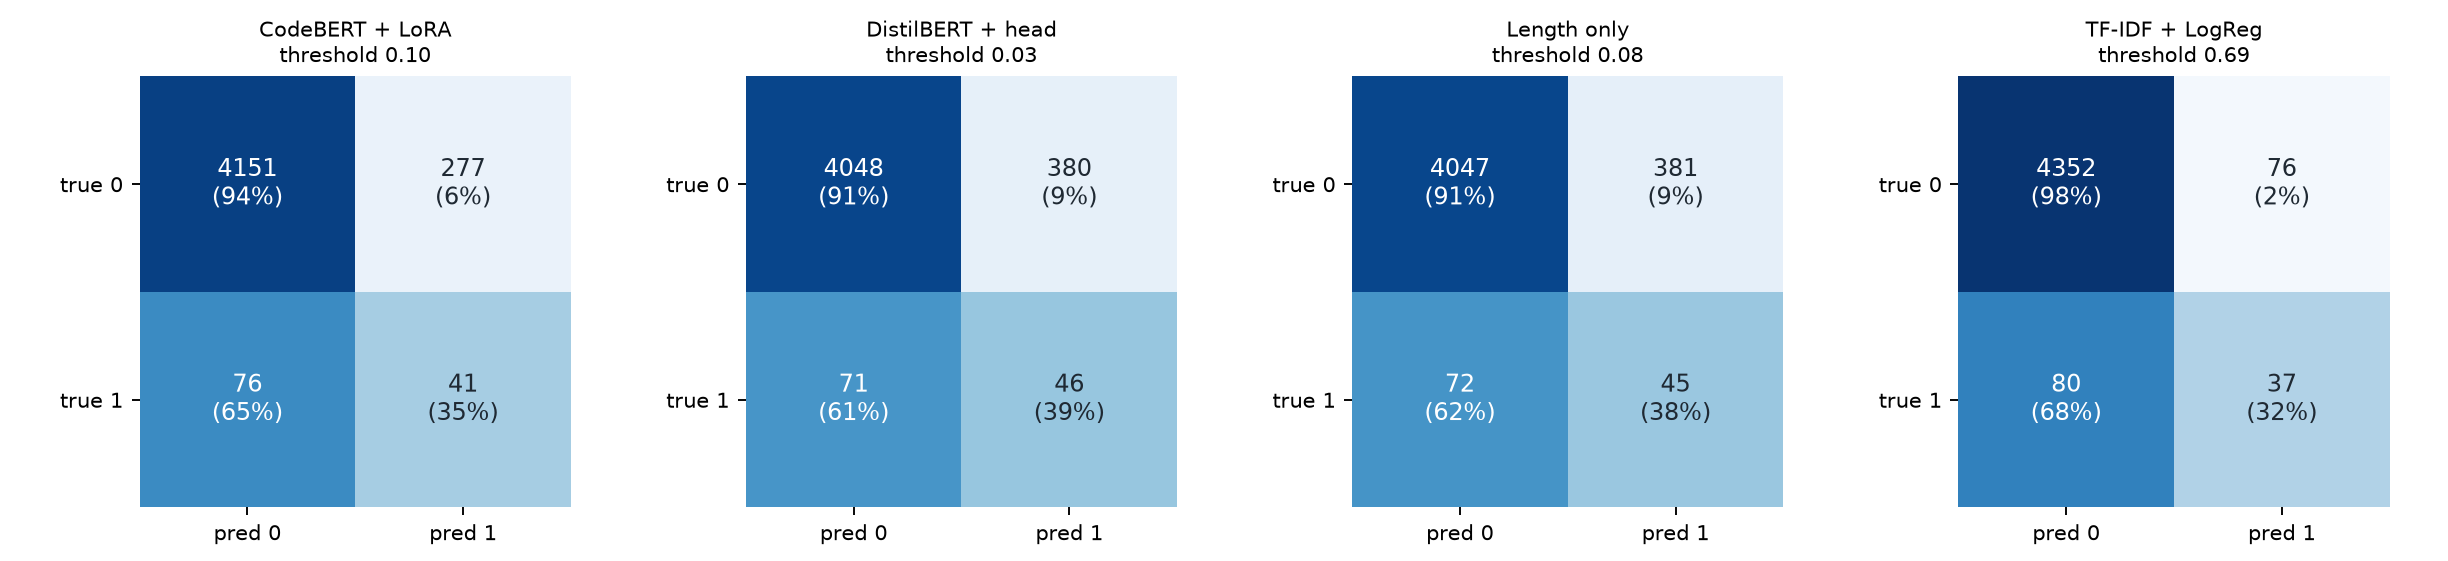

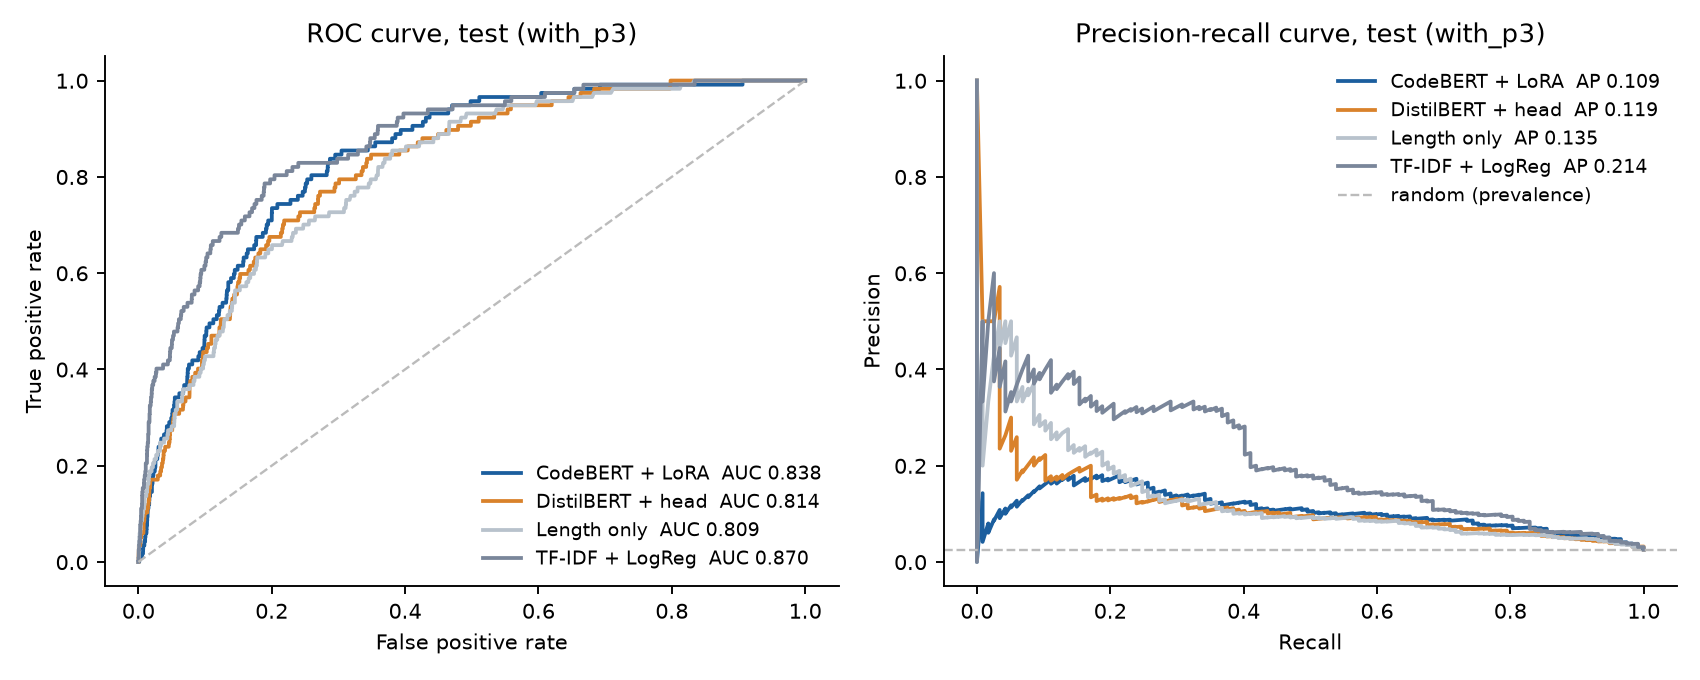

In [13]:
display(Image("results/figures/eval_confusion_with_p3.png"))
display(Image("results/figures/eval_curves_with_p3.png"))

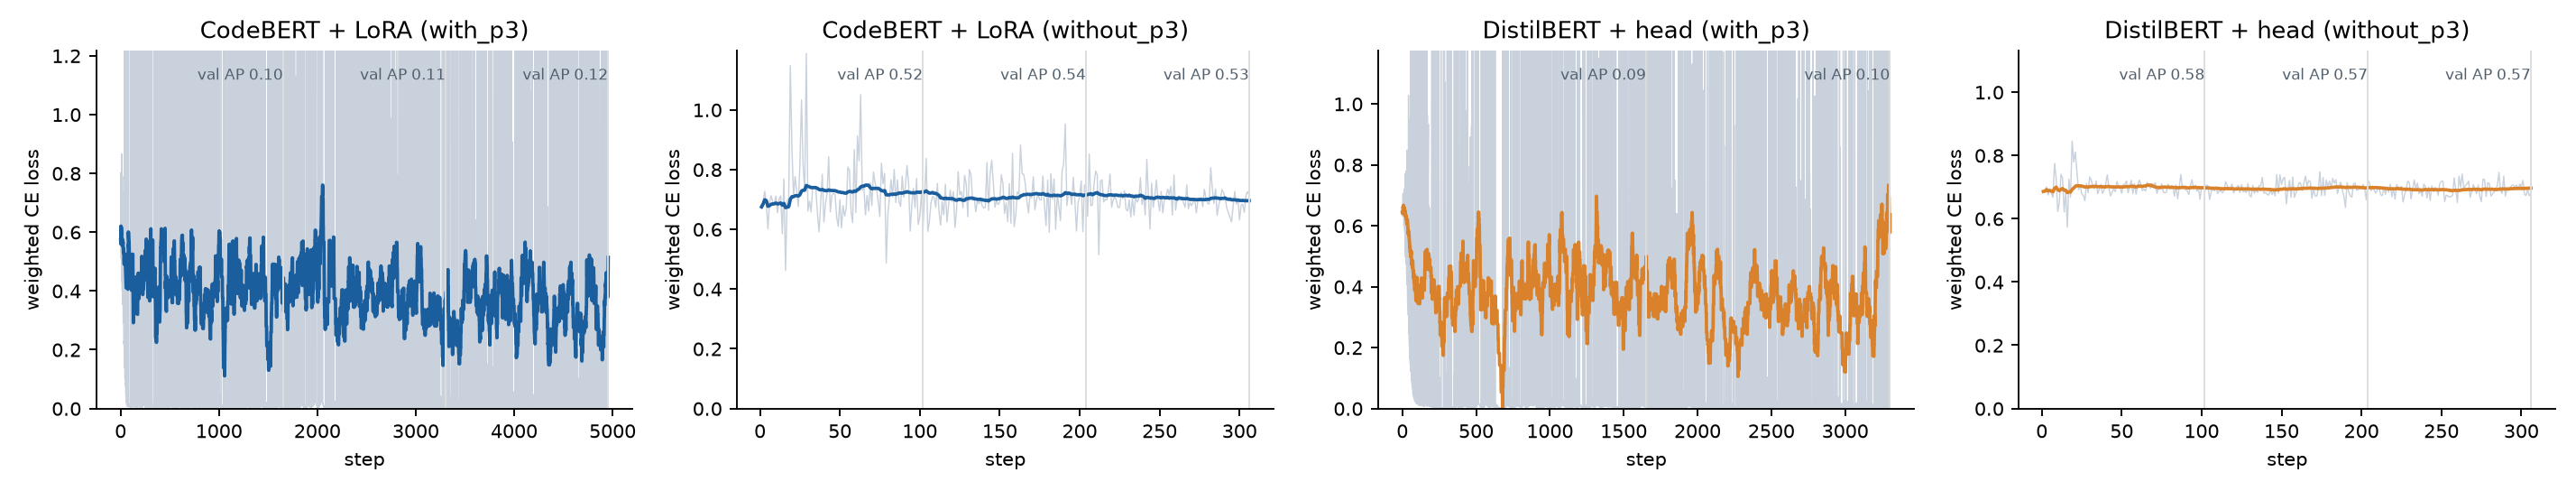

In [14]:
display(Image("results/figures/eval_training_loss.png"))

In [15]:
pd.read_csv("results/per_cwe_recall.csv", index_col=0).head(12).round(2)

,test_positives,CodeBERT + LoRA,DistilBERT + head,Length only,TF-IDF + LogReg
cwe,,,,,
CWE-611,11,0.18,0.18,0.18,0.73
CWE-79,9,0.56,0.56,0.33,0.22
CWE-200,7,0.29,0.29,0.29,0.43
NVD-CWE-noinfo,7,0.43,0.29,0.57,0.00
CWE-352,7,0.00,0.14,0.14,0.14
CWE-20,7,0.57,0.29,0.14,0.14
CWE-287,5,0.60,0.80,0.40,0.20
CWE-835,5,0.20,0.20,0.60,0.20
CWE-264,5,0.00,0.40,0.40,0.20


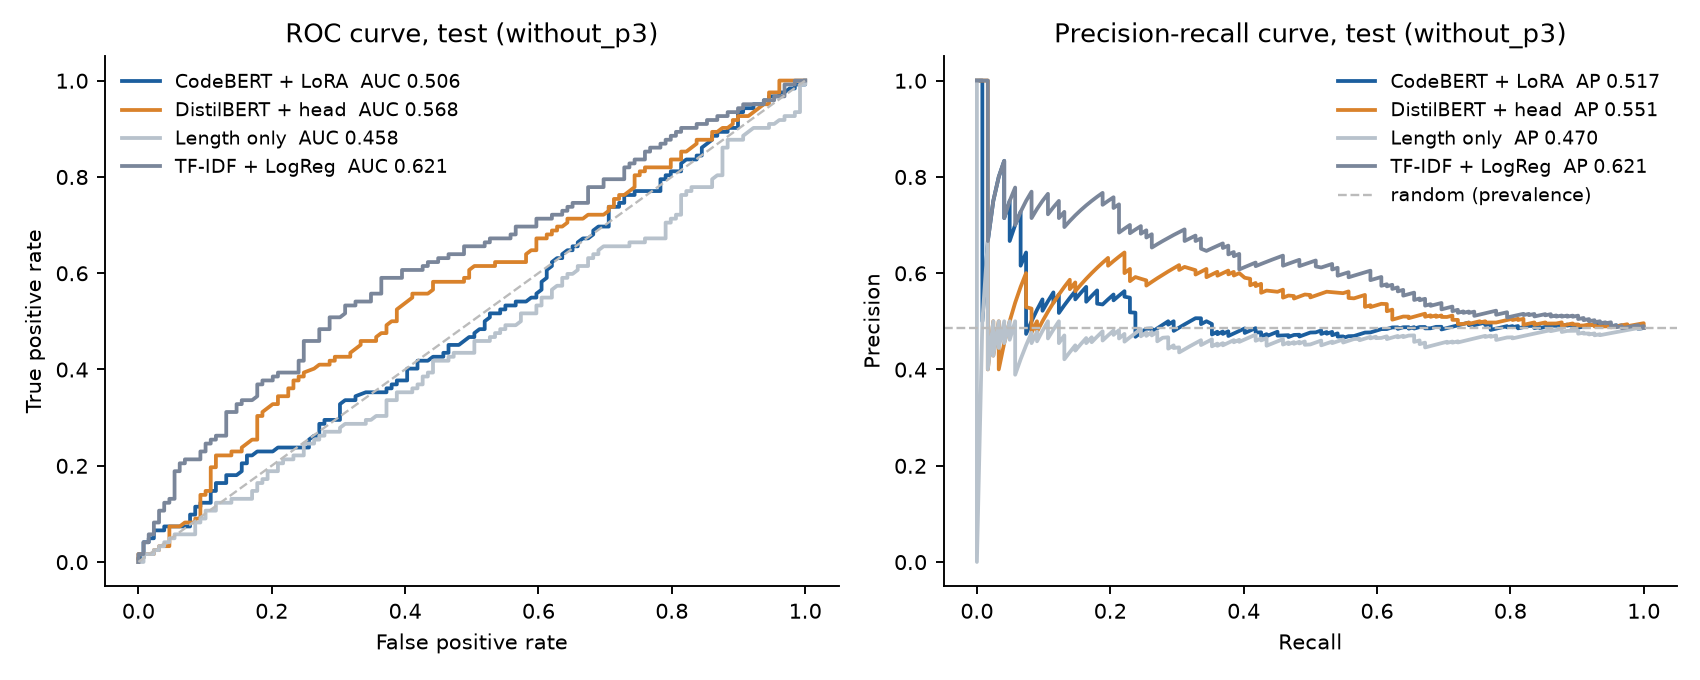

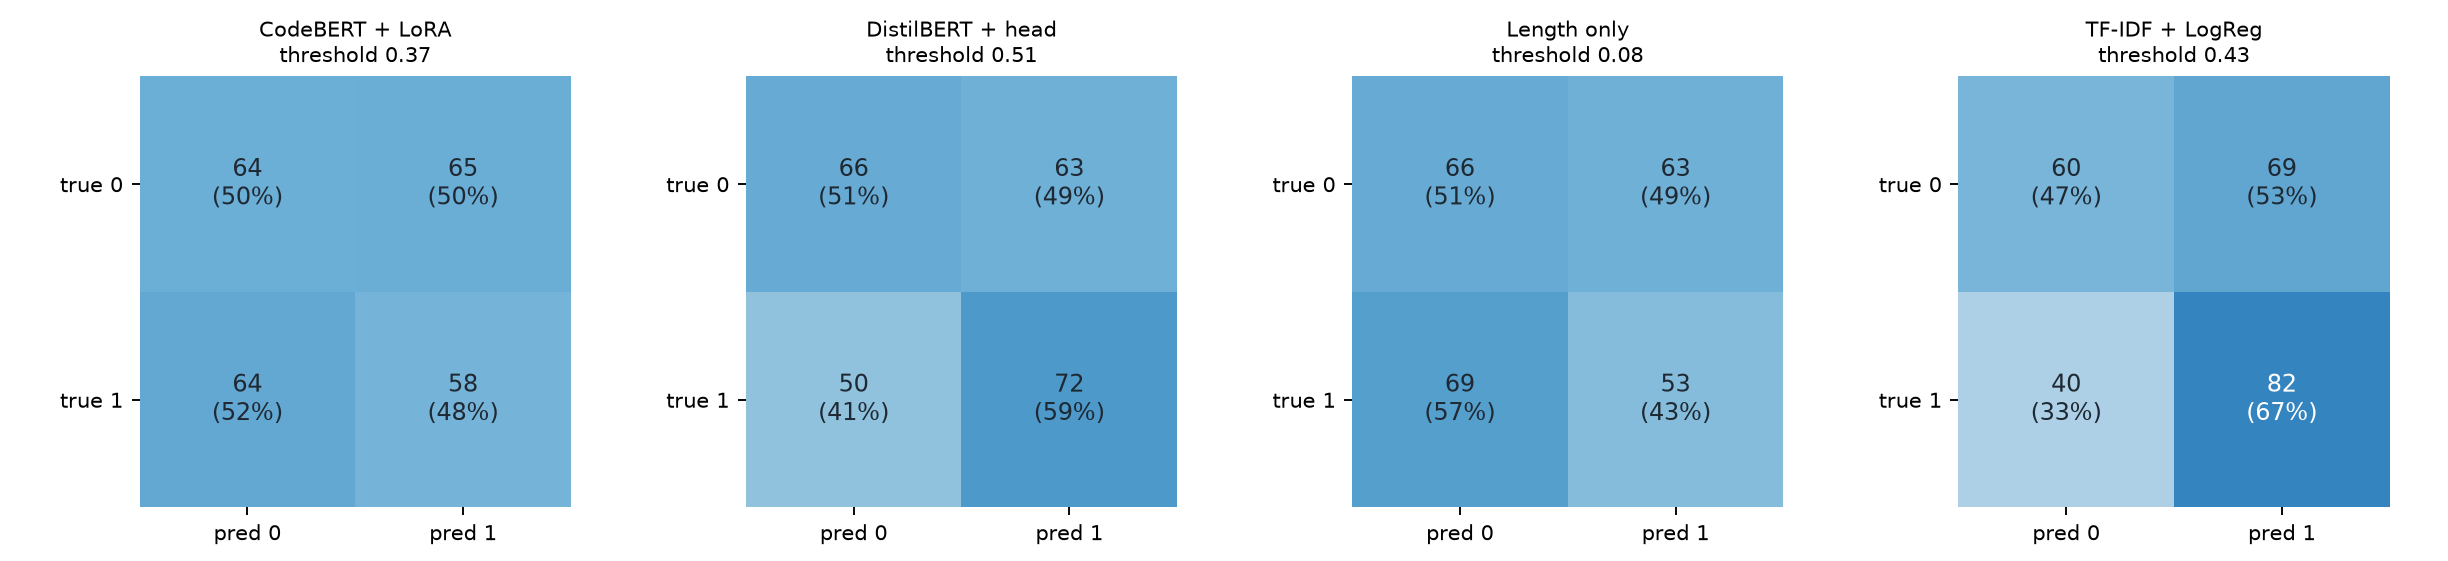

In [16]:
display(Image("results/figures/eval_curves_without_p3.png")); display(Image("results/figures/eval_confusion_without_p3.png"))

## Decision support: what does the model give the organization?
The model ranks Java functions by risk. A security team can only review a limited number of them, so we check how many real vulnerabilities fall into the top-k of the ranking.

In [17]:
p = pd.read_csv("results/runs/codebert_lora_with_p3/test_predictions.csv").sort_values("prob", ascending=False)
total = p.label.sum()
rows = [{"review_top_%": k, "functions_reviewed": int(len(p) * k / 100),
         "vulns_found": int(p.head(int(len(p) * k / 100)).label.sum()),
         "share_of_all_vulns_%": round(100 * p.head(int(len(p) * k / 100)).label.sum() / total, 1)} for k in (1, 2, 5, 10, 20)]
pd.DataFrame(rows)

,review_top_%,functions_reviewed,vulns_found,share_of_all_vulns_%
0,1,45,5,4.3
1,2,90,16,13.7
2,5,227,33,28.2
3,10,454,50,42.7
4,20,909,80,68.4
